# Customer Service Chatbot — Fast Training Notebook

Run the cells from top to bottom in Google Colab. Upload the Bitext CSV when prompted. This notebook cleans the relevant columns, trains a TF-IDF + Logistic Regression intent classifier, evaluates it, and saves the two model files.

**Target columns:** `utterance` → `intent`. The dataset has no response column; predefined replies are in `src/chatbot.py` in the project ZIP.

In [ ]:
from google.colab import files
uploaded = files.upload()  # Select the downloaded Bitext CSV
csv_name = next(name for name in uploaded if name.lower().endswith('.csv'))
print('Uploaded:', csv_name)

Saving customer_support.csv to customer_support (2).csv
Uploaded: customer_support (2).csv


Dataset Shape: (8175, 4)

Missing Values:
flags         0
utterance    87
category     87
intent       87
dtype: int64

Intent Distribution:
intent
check_invoice              324
get_invoice                324
payment_issue              323
review                     315
track_refund               308
set_up_shipping_address    307
place_order                306
cancel_order               305
track_order                305
change_order               304
Name: count, dtype: int64


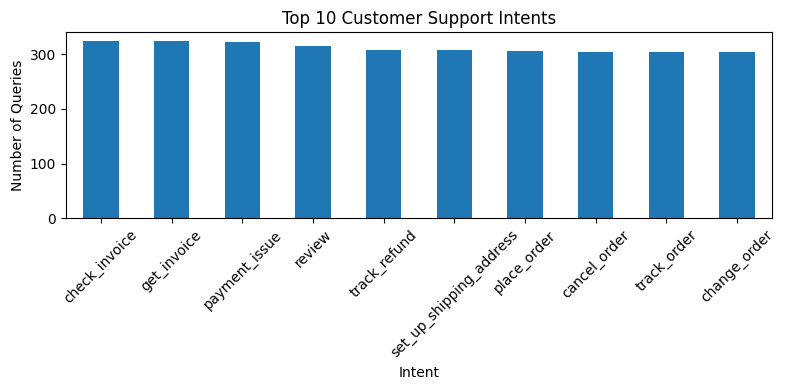

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset using the uploaded csv name
df = pd.read_csv(csv_name)

print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nIntent Distribution:")
print(df["intent"].value_counts().head(10))

# Top 10 intents
df["intent"].value_counts().head(10).plot(kind="bar", figsize=(8, 4))
plt.title("Top 10 Customer Support Intents")
plt.xlabel("Intent")
plt.ylabel("Number of Queries")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The purpose of this code is to **load and explore the customer support dataset before building the chatbot model**. First, I import Pandas for handling and analyzing the dataset and Matplotlib for creating visualizations. The dataset is then loaded from the CSV file using `pd.read_csv(csv_name)` and stored in a DataFrame called `df`. After loading the data, `df.shape` is used to check the **number of rows and columns** in the dataset. Then, `df.isnull().sum()` is used to identify **missing values in each column**, which helps us understand whether the dataset needs cleaning. Next, `df["intent"].value_counts().head(10)` shows the **most frequent customer support intents** in the dataset. Finally, the top 10 intents are displayed using a bar chart. This visualization helps us understand the **distribution of different customer queries** and identify which types of customer support questions occur most frequently. Overall, this code is used for **initial data exploration and understanding the dataset before preprocessing and training the chatbot model**.

In [ ]:
import re
from pathlib import Path
import pandas as pd
def clean_text(value):
    value = str(value).lower().strip()
    value = re.sub(r"[^a-z0-9\s']", ' ', value)
    value = re.sub(r'\s+', ' ', value)
    return value.strip()

# Keep only records with both message and target label, then remove repeated message/intent pairs.
df = df.dropna(subset=['utterance', 'intent']).copy()
df['utterance'] = df['utterance'].map(clean_text)
df['intent'] = df['intent'].astype(str).str.strip()
df = df[(df['utterance'] != '') & (df['intent'] != '')]
df = df.drop_duplicates(subset=['utterance', 'intent'])
print('Usable shape:', df.shape)
print('Intent classes:', df['intent'].nunique())
df[['utterance', 'category', 'intent']].head()

Usable shape: (8077, 4)
Intent classes: 27


,utterance,category,intent
0,i have problems with canceling an order,ORDER,cancel_order
1,how can i find information about canceling orders,ORDER,cancel_order
2,i need help with canceling the last order,ORDER,cancel_order
3,could you help me cancelling the last order i ...,ORDER,cancel_order
4,problem with cancelling an order i made,ORDER,cancel_order


"This is my data preprocessing step. I clean the customer messages by converting them to lowercase, removing unnecessary special characters and extra spaces, then remove missing and duplicate records. Finally, I check how many usable records and unique intents are available. This makes the text data clean and consistent before giving it to the machine learning model."

What each important line does
- str(value).lower() → converts text to lowercase
- .strip() → removes extra spaces from beginning/end
- re.sub(...) → removes unwanted characters
- re.sub(r'\s+', ' ', value) → removes multiple spaces
- dropna() → removes rows with missing utterance or intent
- .map(clean_text) → applies cleaning to every utterance
- astype(str) → makes intent values text/string
- drop_duplicates() → removes duplicate message-intent pairs
- nunique() → counts unique intent classes
- .head() → displays the first few records

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import joblib

X_train, X_test, y_train, y_test = train_test_split(
    df['utterance'], df['intent'], test_size=0.2, random_state=42, stratify=df['intent']
)
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
model = LogisticRegression(max_iter=1500, C=4.0, random_state=42)
model.fit(X_train_vec, y_train)
predictions = model.predict(X_test_vec)

print(f'Test accuracy: {accuracy_score(y_test, predictions):.2%}')
print(classification_report(y_test, predictions, zero_division=0))

Path('models').mkdir(exist_ok=True)
joblib.dump(model, 'models/chatbot_model.pkl')
joblib.dump(vectorizer, 'models/tfidf_vectorizer.pkl')
print('Saved: models/chatbot_model.pkl and models/tfidf_vectorizer.pkl')

Test accuracy: 99.32%
                          precision    recall  f1-score   support

            cancel_order       0.98      0.97      0.98        61
            change_order       1.00      1.00      1.00        61
 change_shipping_address       0.98      1.00      0.99        59
  check_cancellation_fee       0.98      1.00      0.99        58
           check_invoice       1.00      1.00      1.00        65
   check_payment_methods       1.00      1.00      1.00        58
     check_refund_policy       1.00      1.00      1.00        60
               complaint       1.00      1.00      1.00        58
contact_customer_service       1.00      1.00      1.00        58
     contact_human_agent       1.00      1.00      1.00        59
          create_account       0.97      0.98      0.97        57
          delete_account       0.98      0.98      0.98        59
        delivery_options       1.00      1.00      1.00        60
         delivery_period       0.98      1.00      0.

After cleaning the dataset, I split it into 80% training data and 20% testing data. Since machine learning models cannot directly understand text, I used TF-IDF to convert the customer messages into numerical features. Then I trained a Logistic Regression classifier to predict the customer's intent. After training, I tested the model on unseen test data and evaluated it using accuracy, precision, recall, and F1-score. Finally, I saved the trained model and TF-IDF vectorizer using Joblib so that my chatbot can use them later without retraining

1. Train-test split
test_size=0.2


Means:
- 80% → training
- 20% → testing
stratify=df['intent']


Keeps the intent distribution balanced between training and testing data.
2. TF-IDF
TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)


TF-IDF converts text → numbers so the ML model can process it.

ngram_range=(1,2) means:
- (1) → single words: refund
- (2) → two-word combinations: refund request
3. Logistic Regression
model = LogisticRegression(...)
  model.fit(X_train_vec, y_train)


The model learns the relationship between customer messages and their intents.

For example:

"I want my money back" → refund intent

"My card was declined" → card payment issue
4. Prediction
predictions = model.predict(X_test_vec)


The trained model receives unseen customer messages and predicts their intents.
5. Evaluation
accuracy_score(y_test, predictions)


Tells you the overall percentage of correct predictions.
classification_report(...)


Gives:
- Precision → How many predicted examples were actually correct
- Recall → How many actual examples the model successfully found
- F1-score → Balance between precision and recall
6. Saving the model
joblib.dump(model, 'models/chatbot_model.pkl')


Saves your trained Logistic Regression model.
joblib.dump(vectorizer, 'models/tfidf_vectorizer.pkl')

In [ ]:
# Quick sanity test with a few messages
sample_messages = [
    'Where is my order?',
    'I want to get my money back',
    'My payment failed',
]
for message in sample_messages:
    predicted_intent = model.predict(vectorizer.transform([clean_text(message)]))[0]
    print(f'{message}  -->  {predicted_intent}')

Where is my order?  -->  track_order
I want to get my money back  -->  get_refund
My payment failed  -->  payment_issue


After training and evaluating my model, I performed a quick sanity test using some sample customer queries. For each message, I first clean the text, convert it into TF-IDF features using the same vectorizer used during training, and then pass those features to the trained Logistic Regression model. The model predicts the customer's intent, and I print the message along with the predicted intent. This helps me quickly verify that my model is producing sensible predictions before integrating it into the chatbot.

In [ ]:
# Download both trained model files in one ZIP (fewer clicks).
import zipfile
from google.colab import files

with zipfile.ZipFile('chatbot_model_artifacts.zip', 'w', compression=zipfile.ZIP_DEFLATED) as z:
    z.write('models/chatbot_model.pkl', arcname='chatbot_model.pkl')
    z.write('models/tfidf_vectorizer.pkl', arcname='tfidf_vectorizer.pkl')
files.download('chatbot_model_artifacts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

After training and saving my model and TF-IDF vectorizer, I needed to move these files from Google Colab to my local chatbot project. So, I created a ZIP file containing both the trained model and vectorizer. Then I used Google Colab's download function to download the ZIP file to my computer. This makes it easier to transfer both model artifacts together